# Tier 1 Quant Sub-Scores — Complete (merged Part 1 + Part 2, reviewed & patched)

Implements **Step 2** of the Risk Agent build plan end to end: News (GDELT), Vessel, and
Fundamentals sub-scores, the Sanctions multiplier, and the composite Tier 1 score — merged from
two notebooks into one, with **one bug found and fixed during review** (see Section 3 below).
Everything else was checked and is correct as originally built: causal `.shift(1)` baselines for
vessel/fundamentals, backward-only `merge_asof` alignment, explicit `NO_DATA` handling (never a
fabricated 0), and a static (honestly-scoped) sanctions multiplier since no historical sanctions
data exists to vary it by corridor/time.

## 0. Config � check and adjust these before running

In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# --- INPUT ---
# Output of gdelt_preprocessing.ipynb (Step 1). Point this at your real ~151k-row export.
# Both the flattened CSV (locations/entities/keyword_hits as JSON strings) and the full-fidelity
# JSON export are supported and auto-detected by extension.
#
# NOTE: this default points at a small ~9-row sample (built from the pasted example rows) purely
# so this notebook runs end-to-end out of the box. Swap it for your real file before trusting any
# number below.
GDELT_CORPUS_PATH = r"D:\python time\ET\code\risk_agent\csv_backfill\gdelt\outputs\gdelt_relevant_corpus.csv"

# --- OUTPUT ---
OUTPUT_DIR = Path("outputs")
NEWS_SUBSCORE_OUTPUT = OUTPUT_DIR / "tier1_news_subscore.csv"
STORY_SEVERITY_OUTPUT = OUTPUT_DIR / "gdelt_story_severity.csv"  # intermediate, for QC / Part 2 debugging

# --- CORRIDORS ---
# Corridors the risk agent scores. "india" is kept as its own bucket per plan Step 1.4 (it's the
# domestic-policy/demand catch-all after corridor reassignment, not a shipping chokepoint) � it
# still gets a news sub-score, it's just not a strait/chokepoint one. "global" (fundamentals-only,
# e.g. Brent/WTI) has no GDELT presence and is intentionally excluded here.
CORRIDORS = ["hormuz", "bab_el_mandeb", "suez", "red_sea", "persian_gulf", "india"]

# --- ROLLING TIME GRID ---
# How often Tier 1 emits a score per corridor. Plan Step 7 says Tier 1 "runs continuously/hourly";
# 6H is a reasonable default for a backtest/demo grid (dense enough for a 48-72h half-life signal,
# cheap enough to compute over a 13-month backfill). Set to None to auto-derive from the corpus's
# own min/max first_seen_as_of.
GRID_FREQ = "6H"
GRID_START = None  # e.g. "2025-07-01" � None = corpus min date (floored to day)
GRID_END = None    # e.g. "2026-07-19" � None = corpus max date (ceiled to day)

# --- RECENCY DECAY ---
# Half-life in hours for how fast a story's contribution to the rolling average fades. Plan
# Step 2 specifies "~48-72h � this is a fast-moving signal"; 60h is the midpoint.
HALF_LIFE_HOURS = 60.0

# Stories older than this many hours before the scoring timestamp T are dropped from the window
# entirely (pure cost control � at HALF_LIFE_HOURS=60, a 14-day-old story's decay weight is
# already ~2e-17, i.e. functionally zero, so cutting the window here changes nothing numerically).
LOOKBACK_HOURS = 24 * 14

# --- OUTLET CORROBORATION ---
# Separate, tighter window used only to count distinct reporting domains ("is this a corroborated
# multi-outlet story right now, or one lone article still decaying in from days ago").
CORROBORATION_WINDOW_HOURS = 72

# Distinct-domain count at which the corroboration multiplier saturates at its max (1.0).
CORROBORATION_SATURATION = 8

# Corroboration multiplier range. A single-outlet corridor/window still contributes at MIN_MULT
# (never fully zeroed out just because only one domain has reported so far) and scales up to
# MAX_MULT as more independent domains corroborate.
CORROBORATION_MIN_MULT = 0.5
CORROBORATION_MAX_MULT = 1.0

# --- SEVERITY BLEND WEIGHTS (must sum to 1.0) ---
SEVERITY_WEIGHTS = {
    "keyword_severity": 0.55,
    "tfidf_norm": 0.30,
    "mentions_norm": 0.15,
}
assert abs(sum(SEVERITY_WEIGHTS.values()) - 1.0) < 1e-9

# Percentile used to cap tfidf_score / mention_count before min-max normalizing, so a handful of
# extreme outliers (e.g. one story mentioned 44x) don't compress everything else to near-zero.
NORM_CAP_PERCENTILE = 95


## 1. Keyword severity weight table

Reuses the exact `ANCHOR_KEYWORDS` / `CONTEXT_KEYWORDS` vocabulary from Step 1
(`gdelt_preprocessing.ipynb`), but tiers them by how much a single occurrence of that term, on
its own, signals an *acute* supply disruption vs. an *ambient* policy/industry topic.

This table is the one piece of this notebook most worth hand-reviewing/editing � it's a
transparent, auditable stand-in for a real severity model.

In [2]:

KEYWORD_SEVERITY_WEIGHTS = {
    # --- acute / structural disruption : very high confidence signal on its own ---
    "mine": 1.0, "mined": 1.0, "blockade": 1.0, "embargo": 0.95, "chokepoint": 0.9,
    "seize": 0.9, "seized": 0.9, "attack": 0.85, "strike": 0.8, "missile": 0.9,
    "drone": 0.75, "warship": 0.8, "invasion": 0.9, "martial law": 0.85, "curfew": 0.6,

    # --- escalation / military context : meaningful but often reported alongside noise ---
    "war": 0.7, "military": 0.55, "conflict": 0.55, "naval": 0.6, "troops": 0.55,
    "insurgency": 0.6, "coup": 0.7, "escalation": 0.65, "retaliation": 0.6,
    "mobiliz": 0.6, "ceasefire": 0.4,  # ceasefire *can* be de-escalatory, kept moderate not high

    # --- named chokepoints / actors : relevant location/actor anchors, moderate on their own ---
    "hormuz": 0.35, "strait": 0.3, "persian gulf": 0.3, "gulf": 0.2, "red sea": 0.35,
    "red-sea": 0.35, "bab el mandeb": 0.35, "bab-el-mandeb": 0.35, "yemen": 0.3,
    "houthi": 0.55, "iran": 0.25, "sanction": 0.5, "tanker": 0.3, "vessel": 0.2,

    # --- ambient industry / policy topics : relevant but low signal alone ---
    "oil": 0.15, "crude": 0.15, "opec": 0.2, "opec+": 0.2, "refin": 0.15, "pipeline": 0.2,
    "lng": 0.15, "shipping": 0.15, "petrol": 0.15, "fuel": 0.15, "energy": 0.1, "port": 0.1,
}

DEFAULT_KEYWORD_WEIGHT = 0.1  # fallback for any keyword_hit not in the table above (shouldn't
                               # normally happen if Step 1's keyword lists don't change)


## 2. Load the preprocessed GDELT corpus

In [3]:

def load_gdelt_corpus(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"GDELT corpus not found at {path}. Set GDELT_CORPUS_PATH in the config cell to "
            f"your real gdelt_relevant_corpus.csv / .json from gdelt_preprocessing.ipynb."
        )

    if path.suffix.lower() == ".json":
        with open(path) as f:
            records = json.load(f)
        df = pd.DataFrame(records)
    else:
        df = pd.read_csv(path)
        for col in ["entities", "keyword_hits", "locations"]:
            if col in df.columns:
                df[col] = df[col].apply(lambda x: json.loads(x) if isinstance(x, str) else x)

    required = {
        "story_id", "canonical_url", "domain", "corridor_id", "first_seen_as_of",
        "mention_count", "relevance_reason", "keyword_hits", "tfidf_score",
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Corpus is missing expected columns: {missing}")

    df["first_seen_as_of"] = pd.to_datetime(df["first_seen_as_of"], utc=True).dt.tz_localize(None)
    df["mention_count"] = df["mention_count"].astype(int)
    df["tfidf_score"] = df["tfidf_score"].astype(float)
    df["keyword_hits"] = df["keyword_hits"].apply(lambda x: x if isinstance(x, list) else [])

    return df


corpus = load_gdelt_corpus(GDELT_CORPUS_PATH)
print(f"Loaded {len(corpus):,} stories")
print(f"Date range: {corpus['first_seen_as_of'].min()}  ->  {corpus['first_seen_as_of'].max()}")
print()
print("Rows per corridor (raw, before restricting to CORRIDORS list):")
print(corpus["corridor_id"].value_counts())
corpus.head(3)


Loaded 151,922 stories
Date range: 2025-07-02 02:30:00  ->  2026-07-18 16:45:00

Rows per corridor (raw, before restricting to CORRIDORS list):
corridor_id
india            73178
persian_gulf     50200
hormuz           20280
red_sea           6731
bab_el_mandeb     1016
suez               517
Name: count, dtype: int64


,story_id,canonical_url,domain,corridor_id,first_seen_as_of,mention_count,relevance_reason,keyword_hits,tfidf_score,entities,locations
0,20f9ec06efd268f4,//tbsnews.net/worldbiz/middle-east/iran-made-p...,tbsnews.net,hormuz,2025-07-02 02:30:00,1,keyword_match,"[hormuz, iran, strait]",0.122401,[US OFFICIAL|IRAN],[{'source_file': 'D:\python time\ET\code\risk_...
1,01d9e122f614f50a,//aol.co.uk/trump-claims-israel-ready-gaza-020...,aol.co.uk,persian_gulf,2025-07-02 03:00:00,2,keyword_match,[iran],0.000000,"[IRAN|ISRAEL, ISRAEL|IRAN]",[{'source_file': 'D:\python time\ET\code\risk_...
2,b5e53845b8e79368,//thedailystar.net/news/bangladesh/news/kuet-s...,thedailystar.net,india,2025-07-02 03:30:00,1,stage_b_semantic_rescue,[],0.109517,[EDUCATION MINIST|],[{'source_file': 'D:\python time\ET\code\risk_...


In [4]:

# Restrict to the corridors this agent actually scores. Anything else (e.g. a corridor value
# introduced upstream that isn't in CORRIDORS) is dropped here explicitly and reported, rather
# than silently scored into the wrong bucket downstream.
unexpected_corridors = set(corpus["corridor_id"].unique()) - set(CORRIDORS)
if unexpected_corridors:
    print(f"NOTE: dropping {len(corpus[corpus['corridor_id'].isin(unexpected_corridors)]):,} "
          f"rows with corridor_id(s) not in CORRIDORS: {sorted(unexpected_corridors)}")

corpus = corpus[corpus["corridor_id"].isin(CORRIDORS)].reset_index(drop=True)
print(f"{len(corpus):,} stories remain across {corpus['corridor_id'].nunique()} corridors")


151,922 stories remain across 6 corridors


## 3. Story severity proxy

**Fixed during review:** the normalization step below (`tfidf_norm`, `mentions_norm`) originally
used a single global min/max/percentile across the entire corpus, which leaks future months'
statistics into earlier stories' scores -- the same class of lookahead bug Part 2 carefully avoids
elsewhere with `.shift(1)` and trailing windows. Now normalized against a trailing 90-day window
computed per-day and joined back to each story, consistent with the rest of the pipeline.

In [5]:
def keyword_severity_max(hits):
    if not hits:
        return 0.0
    return max(KEYWORD_SEVERITY_WEIGHTS.get(h, DEFAULT_KEYWORD_WEIGHT) for h in hits)


# FIX (found in review): the original version of this cell normalized tfidf_norm/mentions_norm
# with a single global min/max/percentile over the ENTIRE corpus at once. That means a story's
# severity score depended on statistics from months that, at that story's own timestamp, hadn't
# happened yet -- lookahead bias, the same class of bug the vessel/fundamentals sub-scores in
# Part 2 were careful to avoid via .shift(1) and trailing windows. Fixed here to match: normalize
# against a trailing NORM_BASELINE_DAYS window instead of the whole-corpus range. Computed once
# per calendar day (not per story -- a per-story expanding calculation is correct but O(n^2) and
# too slow at 150k+ rows) and joined back onto each story by its day.
NORM_BASELINE_DAYS = 90  # matches the vessel sub-score's baseline window, for consistency

def trailing_capped_minmax_by_day(df, value_col, time_col="first_seen_as_of",
                                   cap_percentile=NORM_CAP_PERCENTILE, baseline_days=NORM_BASELINE_DAYS,
                                   min_obs=20):
    d = df[[time_col, value_col]].copy()
    d["_day"] = d[time_col].dt.floor("D")
    days = np.sort(d["_day"].unique())
    times = d[time_col].values.astype("datetime64[ns]")
    vals = d[value_col].astype(float).values
    order = np.argsort(times)
    times_sorted, vals_sorted = times[order], vals[order]

    day_stats = {}
    baseline = np.timedelta64(baseline_days, "D")
    for day in days:
        day64 = np.datetime64(day)
        lo_idx = np.searchsorted(times_sorted, day64 - baseline, side="left")
        hi_idx = np.searchsorted(times_sorted, day64 + np.timedelta64(1, "D"), side="left")
        window = vals_sorted[lo_idx:hi_idx]
        if len(window) < min_obs:
            day_stats[day] = None  # not enough trailing history yet -- see fallback below
            continue
        cap = np.percentile(window, cap_percentile)
        capped_window = np.clip(window, None, cap) if cap > 0 else window
        lo, hi = capped_window.min(), capped_window.max()
        day_stats[day] = (cap, lo, hi)

    out = np.empty(len(df), dtype=float)
    for i, (t, v) in enumerate(zip(df[time_col].values, df[value_col].astype(float).values)):
        day = pd.Timestamp(t).floor("D")
        stats = day_stats.get(day)
        if stats is None:
            # Not enough trailing history yet (e.g. early in the backfill window) -- fall back to
            # a neutral 0.0 rather than fabricating a normalization off a handful of points. This
            # matches how vessel/fundamentals handle their own warm-up period (NO_DATA / no signal
            # yet), just expressed as a low-confidence severity contribution instead of a NaN,
            # since story_severity is a blend, not a single pass/fail sub-score.
            out[i] = 0.0
            continue
        cap, lo, hi = stats
        capped_v = min(v, cap) if cap > 0 else v
        out[i] = 0.0 if (hi - lo) < 1e-12 else float(np.clip((capped_v - lo) / (hi - lo), 0, 1))
    return out


corpus = corpus.sort_values("first_seen_as_of").reset_index(drop=True)
corpus["keyword_severity"] = corpus["keyword_hits"].apply(keyword_severity_max)
corpus["tfidf_norm"] = trailing_capped_minmax_by_day(corpus, "tfidf_score")
corpus["mentions_norm"] = trailing_capped_minmax_by_day(
    corpus.assign(_log_mentions=np.log1p(corpus["mention_count"])), "_log_mentions"
)

corpus["story_severity"] = (
    SEVERITY_WEIGHTS["keyword_severity"] * corpus["keyword_severity"]
    + SEVERITY_WEIGHTS["tfidf_norm"] * corpus["tfidf_norm"]
    + SEVERITY_WEIGHTS["mentions_norm"] * corpus["mentions_norm"]
).clip(0, 1)

print("story_severity distribution:")
print(corpus["story_severity"].describe())
corpus[["canonical_url", "corridor_id", "keyword_hits", "keyword_severity",
        "tfidf_norm", "mentions_norm", "story_severity"]].sort_values(
    "story_severity", ascending=False
).head(10)

story_severity distribution:
count    151922.000000
mean          0.289770
std           0.169023
min           0.055000
25%           0.168028
50%           0.234166
75%           0.385000
max           1.000000
Name: story_severity, dtype: float64


,canonical_url,corridor_id,keyword_hits,keyword_severity,tfidf_norm,mentions_norm,story_severity
106583,//wpde.com/news/nation-world/iran-foreign-mini...,hormuz,"[blockade, ceasefire, hormuz, iran, naval, oil...",1.0,1.000000,1.000000,1.000000
94302,//cbc.ca/news/world/livestory/trump-vows-to-bl...,hormuz,"[blockade, hormuz, iran, oil, strait, tanker]",1.0,1.000000,1.000000,1.000000
131978,//livemint.com/news/india/after-death-of-3-ind...,hormuz,"[blockade, hormuz, iran, strait]",1.0,1.000000,1.000000,1.000000
95019,//gcaptain.com/oil-tankers-steer-clear-of-horm...,hormuz,"[blockade, hormuz, oil, tanker]",1.0,1.000000,1.000000,1.000000
95095,//dailymaverick.co.za/article/2026-04-13-oil-t...,hormuz,"[blockade, hormuz, oil, tanker]",1.0,1.000000,1.000000,1.000000
106219,//thehindubusinessline.com/news/world/us-turns...,india,"[blockade, iran, naval, tanker]",1.0,1.000000,1.000000,1.000000
94663,//abc.net.au/news/2026-04-13/strait-of-hormuz-...,hormuz,"[blockade, hormuz, iran, strait]",1.0,1.000000,1.000000,1.000000
107663,//economictimes.indiatimes.com/industry/energy...,hormuz,"[blockade, energy, hormuz, iran, oil, strait, ...",1.0,0.987985,1.000000,0.996395
150549,//indianexpress.com/article/world/us-forces-di...,hormuz,"[blockade, iran, missile, oil, tanker]",1.0,1.000000,0.944091,0.991614
148530,//washingtonexaminer.com/policy/defense/464570...,hormuz,"[blockade, hormuz, iran, strait]",1.0,1.000000,0.944091,0.991614


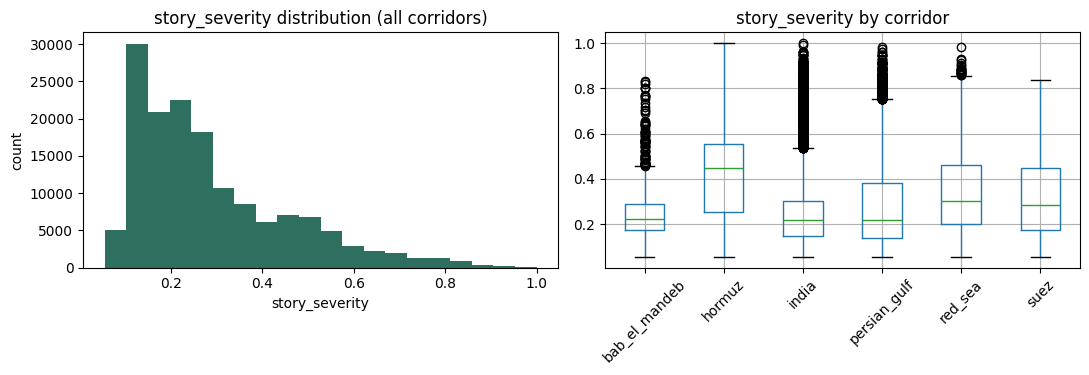

Wrote per-story severity table to outputs\gdelt_story_severity.csv


In [6]:

# Quick QC plot: severity distribution overall and by corridor. Sanity check, not a shipped
# visual � expect a right-skew (most stories ambient, a smaller tail of genuinely acute ones).
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(corpus["story_severity"], bins=20, color="#2f6f5f")
axes[0].set_title("story_severity distribution (all corridors)")
axes[0].set_xlabel("story_severity")
axes[0].set_ylabel("count")

corpus.boxplot(column="story_severity", by="corridor_id", ax=axes[1], rot=45)
axes[1].set_title("story_severity by corridor")
axes[1].set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
corpus.drop(columns=["entities", "locations", "keyword_hits"], errors="ignore").to_csv(
    STORY_SEVERITY_OUTPUT, index=False
)
print(f"Wrote per-story severity table to {STORY_SEVERITY_OUTPUT}")


## 4. Rolling News sub-score

For each corridor and each grid timestamp `T`:

1. Take stories with `first_seen_as_of` in `[T - LOOKBACK_HOURS, T]`.
2. Weight each by exponential recency decay: `0.5 ** (hours_since_story / HALF_LIFE_HOURS)`.
3. `weighted_avg_severity` = decay-weighted average of `story_severity` over that window.
4. Separately count **distinct domains** in the tighter `CORROBORATION_WINDOW_HOURS` window ->
   `corroboration_multiplier` (scaled between `CORROBORATION_MIN_MULT` and `CORROBORATION_MAX_MULT`,
   saturating at `CORROBORATION_SATURATION` distinct outlets).
5. `news_subscore = clip(weighted_avg_severity * corroboration_multiplier, 0, 1)`.

If a corridor has **zero** stories in the lookback window at `T`, the sub-score is written as
`NaN` / `data_status = "NO_DATA"` rather than silently defaulting to 0 � a missing signal is not
a safe signal (same principle plan Step 2 calls out explicitly for the vessel sub-score, applied
consistently here).

Implementation note: this uses `np.searchsorted` on a per-corridor sorted timestamp array rather
than a naive O(grid_points � all_stories) scan, so it stays cheap even at hourly grid resolution
over a full 13-month backfill.

In [7]:

def build_time_grid(corpus, freq, start=None, end=None):
    start = pd.Timestamp(start) if start else corpus["first_seen_as_of"].min().floor("D")
    end = pd.Timestamp(end) if end else corpus["first_seen_as_of"].max().ceil("D")
    return pd.date_range(start, end, freq=freq)


def compute_news_subscore_for_corridor(df_c, grid_times):
    df_c = df_c.sort_values("first_seen_as_of")
    t = df_c["first_seen_as_of"].values.astype("datetime64[ns]")
    sev = df_c["story_severity"].to_numpy()
    dom = df_c["domain"].to_numpy()

    rows = []
    for T in grid_times:
        T64 = np.datetime64(T)
        lo = T64 - np.timedelta64(int(LOOKBACK_HOURS * 3600), "s")
        i0 = np.searchsorted(t, lo, side="left")
        i1 = np.searchsorted(t, T64, side="right")

        if i1 <= i0:
            rows.append({
                "as_of": T, "news_subscore": np.nan, "data_status": "NO_DATA",
                "weighted_avg_severity": np.nan, "corroboration_multiplier": np.nan,
                "outlet_count_corroboration_window": 0, "n_stories_lookback": 0,
            })
            continue

        t_win, sev_win, dom_win = t[i0:i1], sev[i0:i1], dom[i0:i1]
        hours_diff = (T64 - t_win) / np.timedelta64(1, "h")
        decay = 0.5 ** (hours_diff / HALF_LIFE_HOURS)
        decay_sum = decay.sum()
        weighted_avg_severity = float((sev_win * decay).sum() / decay_sum) if decay_sum > 0 else np.nan

        corrob_lo = T64 - np.timedelta64(int(CORROBORATION_WINDOW_HOURS * 3600), "s")
        cj0 = np.searchsorted(t_win, corrob_lo, side="left")
        outlet_count = len(np.unique(dom_win[cj0:])) if len(dom_win[cj0:]) else 0

        saturation_log = np.log1p(CORROBORATION_SATURATION)
        corrob_frac = min(1.0, np.log1p(outlet_count) / saturation_log) if saturation_log > 0 else 0.0
        corrob_mult = CORROBORATION_MIN_MULT + (CORROBORATION_MAX_MULT - CORROBORATION_MIN_MULT) * corrob_frac

        news_subscore = float(np.clip(weighted_avg_severity * corrob_mult, 0, 1)) if not np.isnan(weighted_avg_severity) else np.nan

        rows.append({
            "as_of": T, "news_subscore": news_subscore, "data_status": "OK",
            "weighted_avg_severity": weighted_avg_severity,
            "corroboration_multiplier": float(corrob_mult),
            "outlet_count_corroboration_window": int(outlet_count),
            "n_stories_lookback": int(i1 - i0),
        })

    out = pd.DataFrame(rows)
    out.insert(0, "corridor_id", df_c["corridor_id"].iloc[0] if len(df_c) else None)
    return out


grid_times = build_time_grid(corpus, GRID_FREQ, GRID_START, GRID_END)
print(f"Grid: {len(grid_times):,} timestamps per corridor "
      f"({grid_times.min()} -> {grid_times.max()}, freq={GRID_FREQ})")

news_subscore_parts = []
for corridor in CORRIDORS:
    df_c = corpus[corpus["corridor_id"] == corridor]
    if df_c.empty:
        # Corridor has no stories in this corpus at all (e.g. small sample run) � still emit a
        # fully NO_DATA series for schema consistency downstream, rather than omitting the corridor.
        part = pd.DataFrame({"as_of": grid_times})
        part["corridor_id"] = corridor
        part["news_subscore"] = np.nan
        part["data_status"] = "NO_DATA"
        part["weighted_avg_severity"] = np.nan
        part["corroboration_multiplier"] = np.nan
        part["outlet_count_corroboration_window"] = 0
        part["n_stories_lookback"] = 0
        part = part[["corridor_id", "as_of", "news_subscore", "data_status",
                     "weighted_avg_severity", "corroboration_multiplier",
                     "outlet_count_corroboration_window", "n_stories_lookback"]]
    else:
        part = compute_news_subscore_for_corridor(df_c, grid_times)
    news_subscore_parts.append(part)

news_subscore_df = pd.concat(news_subscore_parts, ignore_index=True)
print(f"\nBuilt {len(news_subscore_df):,} (corridor x timestamp) rows")
news_subscore_df.head()


Grid: 1,529 timestamps per corridor (2025-07-02 00:00:00 -> 2026-07-19 00:00:00, freq=6H)


C:\Users\ejisg\AppData\Local\Temp\ipykernel_9608\1316978493.py:4: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  return pd.date_range(start, end, freq=freq)



Built 9,174 (corridor x timestamp) rows


,corridor_id,as_of,news_subscore,data_status,weighted_avg_severity,corroboration_multiplier,outlet_count_corroboration_window,n_stories_lookback
0,hormuz,2025-07-02 00:00:00,NaN,NO_DATA,NaN,NaN,0,0
1,hormuz,2025-07-02 06:00:00,0.411335,OK,0.474849,0.866243,4,4
2,hormuz,2025-07-02 12:00:00,0.350903,OK,0.350903,1.000000,9,9
3,hormuz,2025-07-02 18:00:00,0.371177,OK,0.371177,1.000000,12,12
4,hormuz,2025-07-03 00:00:00,0.384077,OK,0.384077,1.000000,13,13


## 5. QC

In [8]:

coverage = (
    news_subscore_df.groupby("corridor_id")["data_status"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .round(3)
)
print("Fraction of grid points OK vs NO_DATA, per corridor:")
print(coverage)
print()
print("news_subscore summary stats where data_status == 'OK':")
print(news_subscore_df.loc[news_subscore_df["data_status"] == "OK", "news_subscore"].describe())


Fraction of grid points OK vs NO_DATA, per corridor:
data_status    NO_DATA     OK
corridor_id                  
bab_el_mandeb    0.002  0.998
hormuz           0.001  0.999
india            0.001  0.999
persian_gulf     0.001  0.999
red_sea          0.001  0.999
suez             0.001  0.999

news_subscore summary stats where data_status == 'OK':
count    9165.000000
mean        0.269295
std         0.073461
min         0.061673
25%         0.224318
50%         0.253811
75%         0.307513
max         0.570332
Name: news_subscore, dtype: float64


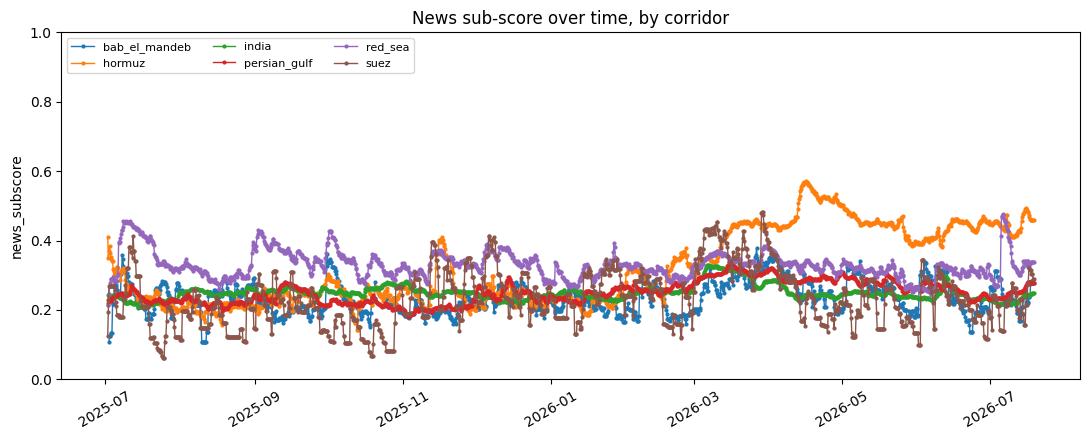


If every corridor here looks flat/empty, you are almost certainly still running against
the small SAMPLE corpus � point GDELT_CORPUS_PATH at your real ~151k-row export and rerun.


In [9]:

fig, ax = plt.subplots(figsize=(11, 4.5))
for corridor, grp in news_subscore_df.groupby("corridor_id"):
    ok = grp[grp["data_status"] == "OK"]
    if ok.empty:
        continue
    ax.plot(ok["as_of"], ok["news_subscore"], marker="o", markersize=2, linewidth=1, label=corridor)

ax.set_title("News sub-score over time, by corridor")
ax.set_ylabel("news_subscore")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=8, ncol=3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nIf every corridor here looks flat/empty, you are almost certainly still running against")
print("the small SAMPLE corpus � point GDELT_CORPUS_PATH at your real ~151k-row export and rerun.")


## 6. Export

In [10]:

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
news_subscore_df.to_csv(NEWS_SUBSCORE_OUTPUT, index=False)
print(f"Wrote {len(news_subscore_df):,} rows to {NEWS_SUBSCORE_OUTPUT}")
print("\nColumns:", list(news_subscore_df.columns))
print("\nThis file is the input Part 2 (Vessel + Fundamentals sub-scores, Sanctions multiplier,")
print("and composite Tier 1 assembly) reads and joins against on (corridor_id, as_of).")


Wrote 9,174 rows to outputs\tier1_news_subscore.csv

Columns: ['corridor_id', 'as_of', 'news_subscore', 'data_status', 'weighted_avg_severity', 'corroboration_multiplier', 'outlet_count_corroboration_window', 'n_stories_lookback']

This file is the input Part 2 (Vessel + Fundamentals sub-scores, Sanctions multiplier,
and composite Tier 1 assembly) reads and joins against on (corridor_id, as_of).


---
# Part 2 — Vessel + Fundamentals, Sanctions, Composite

In [11]:

import json
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# --- INPUTS ---
# Part 1's output. Its (corridor_id, as_of) grid is the master grid everything else aligns to.
NEWS_SUBSCORE_INPUT = Path("outputs/tier1_news_subscore.csv")

# Raw signal exports (same shape as the pipeline's ingestion & normalization layer emits:
# signal_id, corridor_id, as_of, signal_type, metric, value, unit, data_status, confidence, ...).
VESSEL_INPUT = Path(r"D:\python time\ET\code\risk_agent\csv_backfill\vessel\vessel_full_history.csv")
FUNDAMENTALS_INPUT = Path(r"D:\python time\ET\code\risk_agent\csv_backfill\fundamentals\fundamentals_full.csv")

# No historical sanctions file exists (plan.md: "0 rows ... live-only, treat as static multiplier
# not a time series"). Leave as None to use SANCTIONS_STATIC_MULTIPLIER below for every row. If a
# live OFAC/UN/EU pull becomes available later, point this at it — see Section 3 for the expected
# shape and the hook stays a no-op until then.
SANCTIONS_INPUT = None

# --- OUTPUTS ---
OUTPUT_DIR = Path("outputs")
VESSEL_SUBSCORE_OUTPUT = OUTPUT_DIR / "tier1_vessel_subscore.csv"          # intermediate, for QC
FUNDAMENTALS_SUBSCORE_OUTPUT = OUTPUT_DIR / "tier1_fundamentals_subscore.csv"  # intermediate, for QC
TIER1_COMPOSITE_OUTPUT = OUTPUT_DIR / "tier1_composite.csv"

# --- CORRIDORS (must match Part 1) ---
CORRIDORS = ["hormuz", "bab_el_mandeb", "suez", "red_sea", "persian_gulf", "india"]

# Corridors with real vessel AIS coverage today. Anything in CORRIDORS but not here gets an
# explicit NO_DATA vessel sub-score at every timestamp — never a silent 0 (plan Step 2).
VESSEL_COVERED_CORRIDORS = ["hormuz", "bab_el_mandeb", "suez"]

# Shipping corridors the `global` Brent/WTI fundamentals series backs. `india` is handled
# separately below since it has its own basket price series.
GLOBAL_FUNDAMENTALS_CORRIDORS = ["hormuz", "bab_el_mandeb", "suez", "red_sea", "persian_gulf"]

# --- VESSEL SUB-SCORE ---
VESSEL_BASELINE_DAYS = 90          # rolling baseline window, per plan Step 2
VESSEL_MIN_BASELINE_OBS = 14       # need at least this many prior daily obs before trusting a z-score
VESSEL_ROC_PERIOD_DAYS = 7         # rate-of-change horizon for vessel_count_total
VESSEL_Z_SCALE = 3.0               # |z| at which the sub-score saturates at 1.0
VESSEL_BLEND_WEIGHTS = {"congestion_z": 0.6, "count_roc_z": 0.4}
assert abs(sum(VESSEL_BLEND_WEIGHTS.values()) - 1.0) < 1e-9

# --- FUNDAMENTALS SUB-SCORE ---
FUND_TREND_MONTHS = 6              # trailing trend window, per plan Step 2
FUND_MIN_TREND_OBS = 3             # need at least this many prior monthly obs before trusting a deviation
FUND_DEVIATION_SCALE = 0.20        # |% deviation from trend| at which the sub-score saturates at 1.0
                                    # (20% MoM move vs a 6-month trend is already a large macro shock)

# --- SANCTIONS MULTIPLIER ---
# Static baseline per plan Step 2 ("1.0 baseline, 1.15 if any new OFAC/UN designation touches an
# entity linked to the corridor in the current live pull"). No historical data exists to vary this
# by corridor/time, so every row gets the baseline unless SANCTIONS_INPUT is wired up later.
SANCTIONS_STATIC_MULTIPLIER = 1.0
SANCTIONS_DESIGNATION_MULTIPLIER = 1.15  # documented for when live data exists — unused for now

# --- COMPOSITE WEIGHTS (must sum to 1.0; renormalized per-row over whichever sources are OK) ---
COMPOSITE_WEIGHTS = {"news": 0.40, "vessel": 0.35, "fundamentals": 0.25}
assert abs(sum(COMPOSITE_WEIGHTS.values()) - 1.0) < 1e-9


## 1. Master grid — reused directly from Part 1's `news_subscore_df` in memory (no disk round-trip needed within a single merged notebook run)

In [12]:
news_df = news_subscore_df[news_subscore_df["corridor_id"].isin(CORRIDORS)].reset_index(drop=True)

master_grid = (
    news_df[["corridor_id", "as_of"]]
    .drop_duplicates()
    .sort_values(["corridor_id", "as_of"])
    .reset_index(drop=True)
)
print(f"Master grid: {len(master_grid):,} (corridor x timestamp) rows across "
      f"{master_grid['corridor_id'].nunique()} corridors")
print(f"Range: {master_grid['as_of'].min()}  ->  {master_grid['as_of'].max()}")
master_grid.groupby("corridor_id")["as_of"].agg(["min", "max", "count"])

Master grid: 9,174 (corridor x timestamp) rows across 6 corridors
Range: 2025-07-02 00:00:00  ->  2026-07-19 00:00:00


,min,max,count
corridor_id,,,
bab_el_mandeb,2025-07-02,2026-07-19,1529
hormuz,2025-07-02,2026-07-19,1529
india,2025-07-02,2026-07-19,1529
persian_gulf,2025-07-02,2026-07-19,1529
red_sea,2025-07-02,2026-07-19,1529
suez,2025-07-02,2026-07-19,1529


## 2. Vessel sub-score

For each covered corridor, on the vessel data's **native daily grid**:

1. Pivot `metric` into columns (`congestion_index`, `vessel_count_total`, `tanker_capacity_transiting_dwt`).
2. Rolling 90-day baseline mean/std of `congestion_index` (min periods = `VESSEL_MIN_BASELINE_OBS`)
   → `congestion_z = relu((value - baseline_mean) / baseline_std)`. Relu'd because only
   *elevated* congestion is a risk signal — a quiet corridor isn't "anomalously calm" in a way
   that matters here.
3. `VESSEL_ROC_PERIOD_DAYS`-day rate of change of `vessel_count_total`, itself z-scored against
   its own 90-day rolling distribution → `count_roc_z`, then `abs()`'d (a sudden count *drop* —
   ships diverting — is just as much a signal as a sudden *rise* — queuing/backup).
4. Blend the two z-scores, squash to `[0, 1]` by dividing by `VESSEL_Z_SCALE` and clipping.
5. Corridors not in `VESSEL_COVERED_CORRIDORS` get `NO_DATA` at every timestamp — explicit, not a
   silent 0 (plan Step 2 is emphatic about this).

In [13]:

def load_vessel_data(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Vessel data not found at {path}.")
    df = pd.read_csv(path)
    df["as_of"] = pd.to_datetime(df["as_of"], utc=True).dt.tz_localize(None)
    return df


vessel_raw = load_vessel_data(VESSEL_INPUT)
print(f"Loaded {len(vessel_raw):,} vessel signal rows")
print("Corridors:", sorted(vessel_raw['corridor_id'].unique()))
print("Metrics:", sorted(vessel_raw['metric'].unique()))

unexpected = set(vessel_raw["corridor_id"].unique()) - set(VESSEL_COVERED_CORRIDORS)
if unexpected:
    print(f"\nNOTE: vessel data has corridor(s) not in VESSEL_COVERED_CORRIDORS: {sorted(unexpected)} "
          f"— add them there if this is real coverage, otherwise they'll be dropped below.")

vessel_wide = (
    vessel_raw[vessel_raw["corridor_id"].isin(VESSEL_COVERED_CORRIDORS)]
    .pivot_table(index=["corridor_id", "as_of"], columns="metric", values="value", aggfunc="mean")
    .reset_index()
    .sort_values(["corridor_id", "as_of"])
)
vessel_wide.head()


Loaded 3,213 vessel signal rows
Corridors: ['bab_el_mandeb', 'hormuz', 'suez']
Metrics: ['congestion_index', 'tanker_capacity_transiting_dwt', 'vessel_count_total']


metric,corridor_id,as_of,congestion_index,tanker_capacity_transiting_dwt,vessel_count_total
0,bab_el_mandeb,2025-07-14,0.276769,303786.0,26.0
1,bab_el_mandeb,2025-07-15,0.453193,657134.0,33.0
2,bab_el_mandeb,2025-07-16,0.276769,541102.0,26.0
3,bab_el_mandeb,2025-07-17,0.503601,722369.0,35.0
4,bab_el_mandeb,2025-07-18,0.251565,609672.0,25.0


In [14]:

def relu(x):
    return np.maximum(x, 0.0)


def compute_vessel_subscore(df_c):
    df_c = df_c.sort_values("as_of").reset_index(drop=True)
    win = f"{VESSEL_BASELINE_DAYS}D"

    s = df_c.set_index("as_of")["congestion_index"]
    baseline_mean = s.rolling(win, min_periods=VESSEL_MIN_BASELINE_OBS).mean().shift(1)
    baseline_std = s.rolling(win, min_periods=VESSEL_MIN_BASELINE_OBS).std().shift(1)
    congestion_z = relu((s - baseline_mean) / baseline_std.replace(0, np.nan))

    vc = df_c.set_index("as_of")["vessel_count_total"]
    roc = vc.pct_change(VESSEL_ROC_PERIOD_DAYS)
    roc_mean = roc.rolling(win, min_periods=VESSEL_MIN_BASELINE_OBS).mean().shift(1)
    roc_std = roc.rolling(win, min_periods=VESSEL_MIN_BASELINE_OBS).std().shift(1)
    count_roc_z = ((roc - roc_mean) / roc_std.replace(0, np.nan)).abs()

    have_baseline = baseline_mean.notna() & roc_mean.notna()

    blend_z = (
        VESSEL_BLEND_WEIGHTS["congestion_z"] * congestion_z.fillna(0)
        + VESSEL_BLEND_WEIGHTS["count_roc_z"] * count_roc_z.fillna(0)
    )
    vessel_subscore = (blend_z / VESSEL_Z_SCALE).clip(0, 1)

    out = pd.DataFrame({
        "as_of": df_c["as_of"].values,
        "vessel_subscore": np.where(have_baseline.values, vessel_subscore.values, np.nan),
        "data_status": np.where(have_baseline.values, "OK", "NO_DATA"),
        "congestion_z": congestion_z.values,
        "count_roc_z": count_roc_z.values,
        "congestion_index": df_c["congestion_index"].values,
        "vessel_count_total": df_c["vessel_count_total"].values,
    })
    out.insert(0, "corridor_id", df_c["corridor_id"].iloc[0])
    return out


vessel_subscore_parts = []
for corridor in CORRIDORS:
    if corridor not in VESSEL_COVERED_CORRIDORS:
        # No coverage at all for this corridor — explicit NO_DATA on the corridor's own native
        # grid is meaningless (there isn't one), so this gets resolved to NO_DATA at merge time
        # against the master grid in Section 5 instead of fabricated here.
        continue
    df_c = vessel_wide[vessel_wide["corridor_id"] == corridor]
    vessel_subscore_parts.append(compute_vessel_subscore(df_c))

vessel_subscore_df = pd.concat(vessel_subscore_parts, ignore_index=True)
print(f"Built {len(vessel_subscore_df):,} vessel sub-score rows "
      f"across {vessel_subscore_df['corridor_id'].nunique()} covered corridors")
print("\nFraction OK vs NO_DATA per corridor (NO_DATA here = still inside the 90D warm-up window):")
print(vessel_subscore_df.groupby("corridor_id")["data_status"].value_counts(normalize=True).unstack(fill_value=0).round(3))
vessel_subscore_df.loc[vessel_subscore_df["data_status"] == "OK", "vessel_subscore"].describe()


Built 1,071 vessel sub-score rows across 3 covered corridors

Fraction OK vs NO_DATA per corridor (NO_DATA here = still inside the 90D warm-up window):
data_status    NO_DATA     OK
corridor_id                  
bab_el_mandeb    0.059  0.941
hormuz           0.059  0.941
suez             0.059  0.941


count    1008.000000
mean        0.196486
std         0.185617
min         0.000003
25%         0.072413
50%         0.140197
75%         0.257003
max         1.000000
Name: vessel_subscore, dtype: float64

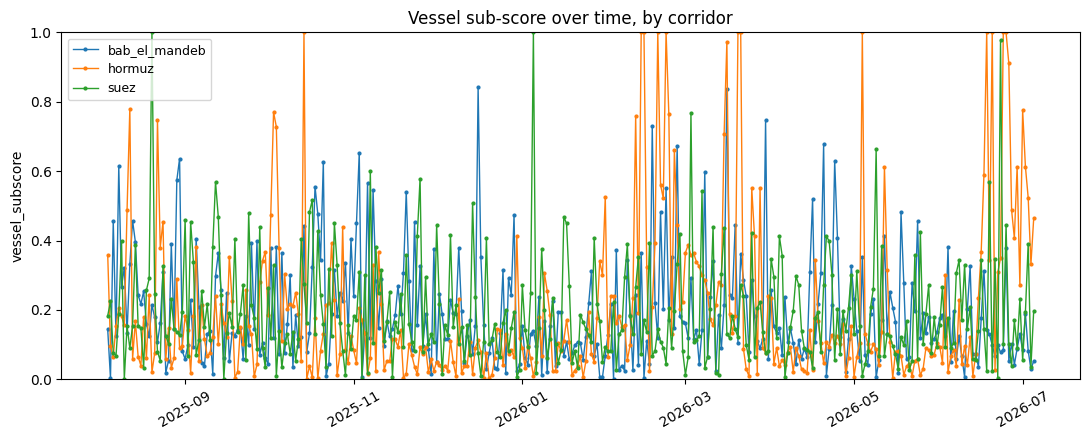

In [15]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4.5))
for corridor, grp in vessel_subscore_df.groupby("corridor_id"):
    ok = grp[grp["data_status"] == "OK"]
    if ok.empty:
        continue
    ax.plot(ok["as_of"], ok["vessel_subscore"], marker="o", markersize=2, linewidth=1, label=corridor)

ax.set_title("Vessel sub-score over time, by corridor")
ax.set_ylabel("vessel_subscore")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=9)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 3. Fundamentals sub-score

Monthly grid, per source series:

1. `global` series (`brent_price`, `wti_price`) averaged into one `global_price_index` per month.
2. `india` series: `indian_basket_price` if present for a given month, else fall back to
   `global_price_index` (the Indian basket only has 1 observed month in the sample data — too
   sparse to trend on its own without a fallback).
3. Trailing `FUND_TREND_MONTHS`-month rolling mean (shifted by 1, so the current month is never
   compared against itself) → `% deviation = (value - trend) / trend`.
4. Sub-score = `abs(% deviation) / FUND_DEVIATION_SCALE`, clipped to `[0, 1]`.
5. Fewer than `FUND_MIN_TREND_OBS` prior months → explicit `NO_DATA`, not a fabricated 0.

**Sanity check to run once real data is in**: plan.md flags a Mar–Apr 2026 Brent spike
($71→$127) as possibly synthetic/injected. If that's in your real `fundamentals_full.csv`, this
sub-score should spike hard around it — that's expected and worth confirming against the actual
cause, not a bug in this notebook.

In [16]:

def load_fundamentals(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Fundamentals data not found at {path}.")
    df = pd.read_csv(path)
    df["as_of"] = pd.to_datetime(df["as_of"], utc=True).dt.tz_localize(None)
    return df


fund_raw = load_fundamentals(FUNDAMENTALS_INPUT)
print(f"Loaded {len(fund_raw):,} fundamentals rows")
print("Corridors:", sorted(fund_raw['corridor_id'].unique()))
print("Metrics:", sorted(fund_raw['metric'].unique()))

fund_raw["month"] = fund_raw["as_of"].dt.to_period("M").dt.to_timestamp("M")

global_price = (
    fund_raw[(fund_raw["corridor_id"] == "global") & (fund_raw["metric"].isin(["brent_price", "wti_price"]))]
    .groupby("month")["value"].mean()
    .rename("global_price_index")
)

india_basket = (
    fund_raw[(fund_raw["corridor_id"] == "india") & (fund_raw["metric"] == "indian_basket_price")]
    .groupby("month")["value"].mean()
    .rename("indian_basket_price")
)

print(f"\nGlobal price index: {len(global_price)} months, "
      f"{global_price.index.min().date()} -> {global_price.index.max().date()}")
print(f"Indian basket price: {len(india_basket)} months "
      f"({'sparse — fallback to global will apply for missing months' if len(india_basket) < FUND_MIN_TREND_OBS else 'sufficient on its own'})")


Loaded 47 fundamentals rows
Corridors: ['global', 'india']
Metrics: ['brent_price', 'crude_import', 'crude_processed', 'indian_basket_price', 'product_consumption', 'wti_price']

Global price index: 12 months, 2025-07-31 -> 2026-06-30
Indian basket price: 1 months (sparse — fallback to global will apply for missing months)


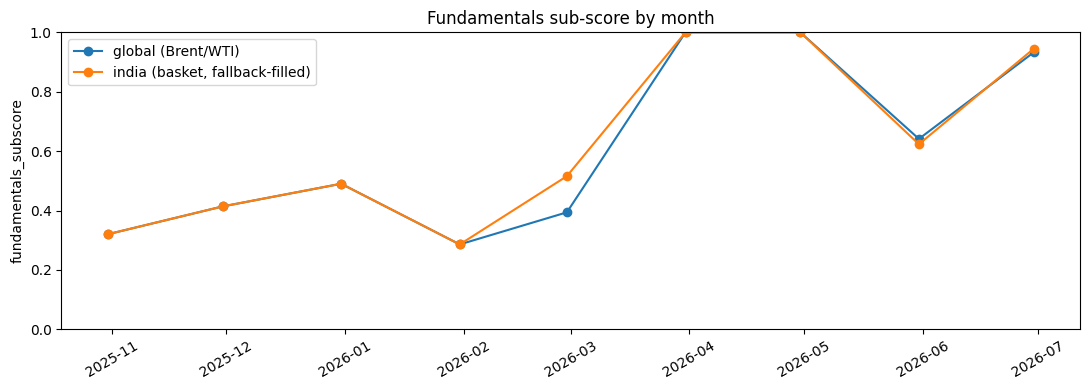

,fundamentals_subscore,pct_deviation,data_status
month,,,
2026-02-28,0.393977,0.078795,OK
2026-03-31,1.000000,0.776772,OK
2026-04-30,1.000000,0.600495,OK
2026-05-31,0.641246,0.128249,OK
2026-06-30,0.932546,-0.186509,OK


In [17]:

def deviation_subscore(series):
    """Given a monthly price series, return (subscore, data_status, pct_deviation) per month."""
    trend = series.rolling(FUND_TREND_MONTHS, min_periods=FUND_MIN_TREND_OBS).mean().shift(1)
    pct_dev = (series - trend) / trend
    subscore = (pct_dev.abs() / FUND_DEVIATION_SCALE).clip(0, 1)
    status = np.where(trend.notna(), "OK", "NO_DATA")
    return pd.DataFrame({"fundamentals_subscore": subscore, "pct_deviation": pct_dev, "data_status": status}, index=series.index)


global_fund = deviation_subscore(global_price)

# India: use its own basket where present, fall back to the global series for months it lacks
# (documented assumption above — 1 real observed month isn't enough to trend on its own yet).
india_series = india_basket.reindex(global_price.index).combine_first(global_price)
india_fund = deviation_subscore(india_series)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(global_fund.index, global_fund["fundamentals_subscore"], marker="o", label="global (Brent/WTI)")
ax.plot(india_fund.index, india_fund["fundamentals_subscore"], marker="o", label="india (basket, fallback-filled)")
ax.set_title("Fundamentals sub-score by month")
ax.set_ylabel("fundamentals_subscore")
ax.set_ylim(0, 1)
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

global_fund.tail()


## 4. Sanctions multiplier

No historical sanctions data exists (`fundamentals_full.csv`'s sibling sanctions export has 0
rows — see plan.md's data-state table). Per plan Step 2, this is **not a time series**: it's a
static multiplier applied to the composite, defaulting to `SANCTIONS_STATIC_MULTIPLIER` (1.0)
everywhere until a live OFAC/UN/EU pull is wired in.

`get_sanctions_multiplier()` below is the seam where that live pull plugs in later — it currently
always returns the static baseline, but takes `corridor_id` so a real implementation can look up
whether any current designation touches an entity linked to that corridor.

In [18]:

def get_sanctions_multiplier(corridor_id, as_of=None, live_designations=None):
    """
    Returns the sanctions multiplier for a corridor. Static baseline for now — no historical
    backfill is possible (plan.md), so every corridor/timestamp gets SANCTIONS_STATIC_MULTIPLIER
    until SANCTIONS_INPUT points at a real live OFAC/UN/EU feed.

    Once that feed exists, the intended shape is: pass today's live_designations (set of entities
    with active designations), check whether any are linked to `corridor_id` (e.g. via the
    knowledge graph's supplier-route-refinery entities), and return
    SANCTIONS_DESIGNATION_MULTIPLIER instead of the baseline when true.
    """
    if SANCTIONS_INPUT is None or live_designations is None:
        return SANCTIONS_STATIC_MULTIPLIER
    # Placeholder for when live data exists — not exercised today.
    corridor_designated = False  # would check live_designations against a corridor->entity map
    return SANCTIONS_DESIGNATION_MULTIPLIER if corridor_designated else SANCTIONS_STATIC_MULTIPLIER


sanctions_multiplier_by_corridor = {c: get_sanctions_multiplier(c) for c in CORRIDORS}
print("Sanctions multiplier per corridor (static baseline — no live feed wired up yet):")
print(sanctions_multiplier_by_corridor)


Sanctions multiplier per corridor (static baseline — no live feed wired up yet):
{'hormuz': 1.0, 'bab_el_mandeb': 1.0, 'suez': 1.0, 'red_sea': 1.0, 'persian_gulf': 1.0, 'india': 1.0}


## 5. Align everything onto the master grid

Vessel (daily) and Fundamentals (monthly) are lower-frequency than the News master grid (6H).
Both are forward-filled onto it with `merge_asof` — using the most recent known value up to each
grid timestamp, never a future one — which is the correct behavior for slow-moving signals
(plan Step 2 explicitly calls Fundamentals "your slowest-moving, most macro sub-score", so
forward-filling it across the gaps between monthly prints is the intended semantics, not a
shortcut). Timestamps before a corridor's first real observation stay `NO_DATA`.

In [19]:

def asof_align(master, source_df, value_col, status_col, corridor_col="corridor_id", time_col="as_of"):
    """Forward-fill `source_df`'s value/status columns onto `master`'s (corridor, as_of) grid."""
    out_parts = []
    for corridor, g_master in master.groupby(corridor_col):
        g_source = source_df[source_df[corridor_col] == corridor].sort_values(time_col)
        if g_source.empty:
            part = g_master[[corridor_col, time_col]].copy()
            part[value_col] = np.nan
            part[status_col] = "NO_DATA"
            out_parts.append(part)
            continue
        merged = pd.merge_asof(
            g_master.sort_values(time_col),
            g_source[[time_col, value_col, status_col]].dropna(subset=[value_col]).sort_values(time_col),
            on=time_col, direction="backward",
        )
        merged[status_col] = merged[status_col].fillna("NO_DATA")
        out_parts.append(merged[[corridor_col, time_col, value_col, status_col]])
    return pd.concat(out_parts, ignore_index=True)


vessel_aligned = asof_align(master_grid, vessel_subscore_df, "vessel_subscore", "data_status")
vessel_aligned = vessel_aligned.rename(columns={"data_status": "vessel_data_status"})

fund_long = pd.concat([
    global_fund.reset_index().rename(columns={"month": "as_of"}).assign(corridor_id="__global__"),
    india_fund.reset_index().rename(columns={"month": "as_of"}).assign(corridor_id="india"),
], ignore_index=True)[["corridor_id", "as_of", "fundamentals_subscore", "data_status"]]

fund_aligned_parts = []
for corridor in CORRIDORS:
    src_key = "india" if corridor == "india" else "__global__"
    src = fund_long[fund_long["corridor_id"] == src_key].assign(corridor_id=corridor)
    fund_aligned_parts.append(
        asof_align(master_grid[master_grid["corridor_id"] == corridor], src,
                   "fundamentals_subscore", "data_status")
    )
fund_aligned = pd.concat(fund_aligned_parts, ignore_index=True).rename(
    columns={"data_status": "fundamentals_data_status"}
)

print(f"vessel_aligned:      {len(vessel_aligned):,} rows")
print(f"fundamentals_aligned: {len(fund_aligned):,} rows")
vessel_aligned.groupby("corridor_id")["vessel_data_status"].value_counts(normalize=True).unstack(fill_value=0).round(3)


vessel_aligned:      9,174 rows
fundamentals_aligned: 9,174 rows


vessel_data_status,NO_DATA,OK
corridor_id,,
bab_el_mandeb,0.086,0.914
hormuz,0.086,0.914
india,1.000,0.000
persian_gulf,1.000,0.000
red_sea,1.000,0.000
suez,0.086,0.914


## 6. Composite Tier 1 score

`tier1_composite_score` = weighted sum of whichever sub-scores are `OK` at this `(corridor_id,
as_of)`, weights renormalized over just those, times the sanctions multiplier — exactly as
specified in plan Step 2. A row with zero `OK` sub-scores gets `NO_DATA` for the composite too,
never a fabricated 0.

In [20]:

composite = (
    news_df[["corridor_id", "as_of", "news_subscore", "data_status"]]
    .rename(columns={"data_status": "news_data_status"})
    .merge(vessel_aligned, on=["corridor_id", "as_of"], how="left")
    .merge(fund_aligned, on=["corridor_id", "as_of"], how="left")
)
composite["sanctions_multiplier"] = composite["corridor_id"].map(sanctions_multiplier_by_corridor)


def weighted_composite(row):
    scores = {
        "news": (row["news_subscore"], row["news_data_status"]),
        "vessel": (row["vessel_subscore"], row["vessel_data_status"]),
        "fundamentals": (row["fundamentals_subscore"], row["fundamentals_data_status"]),
    }
    available = {k: v for k, (v, status) in scores.items() if status == "OK" and pd.notna(v)}
    if not available:
        return pd.Series({"tier1_composite_score": np.nan, "n_sources_available": 0,
                           "sources_used": ""})
    total_w = sum(COMPOSITE_WEIGHTS[k] for k in available)
    raw = sum(COMPOSITE_WEIGHTS[k] * v for k, v in available.items()) / total_w
    score = float(np.clip(raw * row["sanctions_multiplier"], 0, 1))
    return pd.Series({"tier1_composite_score": score, "n_sources_available": len(available),
                       "sources_used": "+".join(sorted(available))})


composite = pd.concat([composite, composite.apply(weighted_composite, axis=1)], axis=1)
composite["data_status"] = np.where(composite["n_sources_available"] > 0, "OK", "NO_DATA")

print(f"Built {len(composite):,} composite rows")
composite.head()


Built 9,174 composite rows


,corridor_id,as_of,news_subscore,news_data_status,vessel_subscore,vessel_data_status,fundamentals_subscore,fundamentals_data_status,sanctions_multiplier,tier1_composite_score,n_sources_available,sources_used,data_status
0,hormuz,2025-07-02 00:00:00,NaN,NO_DATA,NaN,NO_DATA,NaN,NO_DATA,1.0,NaN,0,,NO_DATA
1,hormuz,2025-07-02 06:00:00,0.411335,OK,NaN,NO_DATA,NaN,NO_DATA,1.0,0.411335,1,news,OK
2,hormuz,2025-07-02 12:00:00,0.350903,OK,NaN,NO_DATA,NaN,NO_DATA,1.0,0.350903,1,news,OK
3,hormuz,2025-07-02 18:00:00,0.371177,OK,NaN,NO_DATA,NaN,NO_DATA,1.0,0.371177,1,news,OK
4,hormuz,2025-07-03 00:00:00,0.384077,OK,NaN,NO_DATA,NaN,NO_DATA,1.0,0.384077,1,news,OK


## 7. QC

In [21]:

print("Composite data_status coverage by corridor:")
print(composite.groupby("corridor_id")["data_status"].value_counts(normalize=True).unstack(fill_value=0).round(3))

print("\nHow many sources feed the composite, by corridor (mean, among OK rows):")
print(composite[composite["data_status"] == "OK"].groupby("corridor_id")["n_sources_available"].mean().round(2))

print("\nMost common source combination per corridor:")
print(composite[composite["data_status"] == "OK"].groupby("corridor_id")["sources_used"]
      .agg(lambda s: s.value_counts().idxmax()))

print("\ntier1_composite_score summary, OK rows only:")
print(composite.loc[composite["data_status"] == "OK", "tier1_composite_score"].describe())


Composite data_status coverage by corridor:
data_status    NO_DATA     OK
corridor_id                  
bab_el_mandeb    0.002  0.998
hormuz           0.001  0.999
india            0.001  0.999
persian_gulf     0.001  0.999
red_sea          0.001  0.999
suez             0.001  0.999

How many sources feed the composite, by corridor (mean, among OK rows):
corridor_id
bab_el_mandeb    2.60
hormuz           2.60
india            1.68
persian_gulf     1.68
red_sea          1.68
suez             2.60
Name: n_sources_available, dtype: float64

Most common source combination per corridor:
corridor_id
bab_el_mandeb    fundamentals+news+vessel
hormuz           fundamentals+news+vessel
india                   fundamentals+news
persian_gulf            fundamentals+news
red_sea                 fundamentals+news
suez             fundamentals+news+vessel
Name: sources_used, dtype: object

tier1_composite_score summary, OK rows only:
count    9165.000000
mean        0.327982
std         0.119037
min 

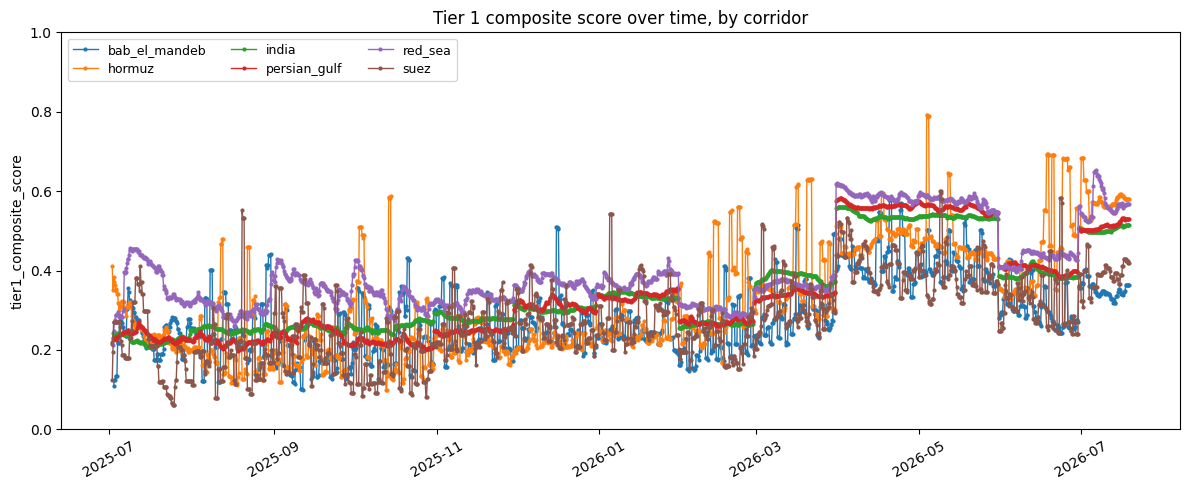

If every corridor here looks flat/empty, check that NEWS_SUBSCORE_INPUT, VESSEL_INPUT, and
FUNDAMENTALS_INPUT are pointed at your real files rather than a tiny sample export.


In [22]:

fig, ax = plt.subplots(figsize=(12, 5))
for corridor, grp in composite.groupby("corridor_id"):
    ok = grp[grp["data_status"] == "OK"]
    if ok.empty:
        continue
    ax.plot(ok["as_of"], ok["tier1_composite_score"], marker="o", markersize=2, linewidth=1, label=corridor)

ax.set_title("Tier 1 composite score over time, by corridor")
ax.set_ylabel("tier1_composite_score")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=9, ncol=3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("If every corridor here looks flat/empty, check that NEWS_SUBSCORE_INPUT, VESSEL_INPUT, and")
print("FUNDAMENTALS_INPUT are pointed at your real files rather than a tiny sample export.")


## 8. Preview only — Step 4 trigger check

Not part of Step 2 proper, but a cheap sanity check that this output is actually usable for
Step 4's trigger condition (plan Step 4.1: fire when the Tier 1 composite crosses a threshold, or
when sub-scores disagree with each other). This just flags candidate rows here for a quick look —
the real trigger logic belongs in its own Step 4 notebook, not here.

In [23]:

PREVIEW_COMPOSITE_THRESHOLD = 0.6      # placeholder — tune in Step 5 calibration
PREVIEW_DISAGREEMENT_THRESHOLD = 0.35  # placeholder — tune in Step 5 calibration

sub_cols = ["news_subscore", "vessel_subscore", "fundamentals_subscore"]
composite["preview_subscore_spread"] = composite[sub_cols].max(axis=1) - composite[sub_cols].min(axis=1)
composite["preview_tier2_trigger"] = (
    (composite["tier1_composite_score"] >= PREVIEW_COMPOSITE_THRESHOLD)
    | (composite["preview_subscore_spread"] >= PREVIEW_DISAGREEMENT_THRESHOLD)
) & (composite["data_status"] == "OK")

print(f"Preview trigger rate by corridor (placeholder thresholds — not yet calibrated per Step 5):")
print(composite.groupby("corridor_id")["preview_tier2_trigger"].mean().round(3))


Preview trigger rate by corridor (placeholder thresholds — not yet calibrated per Step 5):
corridor_id
bab_el_mandeb    0.394
hormuz           0.419
india            0.282
persian_gulf     0.288
red_sea          0.233
suez             0.368
Name: preview_tier2_trigger, dtype: float64


## 9. Export

In [24]:

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

vessel_subscore_df.to_csv(VESSEL_SUBSCORE_OUTPUT, index=False)
fund_long.to_csv(FUNDAMENTALS_SUBSCORE_OUTPUT, index=False)

export_cols = [
    "corridor_id", "as_of", "tier1_composite_score", "data_status", "n_sources_available", "sources_used",
    "news_subscore", "news_data_status",
    "vessel_subscore", "vessel_data_status",
    "fundamentals_subscore", "fundamentals_data_status",
    "sanctions_multiplier",
]
composite[export_cols].to_csv(TIER1_COMPOSITE_OUTPUT, index=False)

print(f"Wrote {len(vessel_subscore_df):,} rows to {VESSEL_SUBSCORE_OUTPUT}")
print(f"Wrote {len(fund_long):,} rows to {FUNDAMENTALS_SUBSCORE_OUTPUT}")
print(f"Wrote {len(composite):,} rows to {TIER1_COMPOSITE_OUTPUT}")
print("\nColumns:", export_cols)
print("\nThis is the Tier 1 half of the Step 0 output schema's sub_scores block — Step 4's")
print("Hawk/Dove/Adjudicator notebook reads this, joins in retrieved evidence, and fills in the")
print("hawk/dove/adjudicator fields only for rows where preview_tier2_trigger (Section 8) is True.")


Wrote 1,071 rows to outputs\tier1_vessel_subscore.csv
Wrote 24 rows to outputs\tier1_fundamentals_subscore.csv
Wrote 9,174 rows to outputs\tier1_composite.csv

Columns: ['corridor_id', 'as_of', 'tier1_composite_score', 'data_status', 'n_sources_available', 'sources_used', 'news_subscore', 'news_data_status', 'vessel_subscore', 'vessel_data_status', 'fundamentals_subscore', 'fundamentals_data_status', 'sanctions_multiplier']

This is the Tier 1 half of the Step 0 output schema's sub_scores block — Step 4's
Hawk/Dove/Adjudicator notebook reads this, joins in retrieved evidence, and fills in the
hawk/dove/adjudicator fields only for rows where preview_tier2_trigger (Section 8) is True.
